# Household Waste Put to Beneficial Use, Nonthaburi Province

**Data:** `data/raw/benefit.csv` — amount of waste put back to use (tonnes), e.g. recycling, composting, fuel, per local government per month, Buddhist Era 2563–2567 (2020–2024)

**Steps:** load → check → convert data types → save `clean_benefit.csv` → overview charts (the original dashboard) + extra charts: share by district, heatmap, best-performing local governments, number of active local governments, and the **beneficial-use rate relative to all waste**

# ปริมาณขยะมูลฝอยในครัวเรือนที่นำไปใช้ประโยชน์ จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/benefit.csv` — ปริมาณขยะที่ถูกนำกลับไปใช้ประโยชน์ (ตัน) เช่น รีไซเคิล ทำปุ๋ย ทำเชื้อเพลิง ราย อปท. รายเดือน พ.ศ. 2563–2567

**ขั้นตอน:** โหลด → ตรวจสอบ → แปลงชนิดข้อมูล → บันทึก `clean_benefit.csv` → กราฟภาพรวม (dashboard เดิม) + กราฟเพิ่มเติม: สัดส่วนรายอำเภอ, heatmap, อปท. ที่ทำได้ดี, จำนวน อปท. ที่มีกิจกรรม และ **อัตราการนำไปใช้ประโยชน์เทียบกับขยะทั้งหมด**

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/benefit.csv` — the `ขยะนำไปใช้ประโยชน์` (waste put to use) column is already numeric

**โหลดข้อมูลดิบ** จาก `../data/raw/benefit.csv` — คอลัมน์ `ขยะนำไปใช้ประโยชน์` เป็นตัวเลขอยู่แล้ว

In [2]:
df = pd.read_csv('../data/raw/benefit.csv')
df

,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะนำไปใช้ประโยชน์
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,0.00
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,0.00
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,0.00
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,0.00
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,0.00
...,...,...,...,...,...,...
2650,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,0.00
2651,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,0.00
2652,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางศรีเมือง,0.22
2653,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,อบต.บางไผ่,0.00


**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ปี                  2655 non-null   int64  
 1   เดือน               2655 non-null   object 
 2   จังหวัด             2655 non-null   object 
 3   อำเภอ               2655 non-null   object 
 4   อปท                 2655 non-null   object 
 5   ขยะนำไปใช้ประโยชน์  2655 non-null   float64
dtypes: float64(1), int64(1), object(4)
memory usage: 124.6+ KB


**Check for duplicate rows** with `duplicated().sum()` — 0 means no rows are identical in every column, so nothing needs to be removed

**ตรวจแถวซ้ำ** ด้วย `duplicated().sum()` — ถ้าได้ 0 แปลว่าไม่มีแถวที่ข้อมูลเหมือนกันทุกคอลัมน์ ไม่ต้องลบอะไร

In [4]:
df.duplicated().sum()

np.int64(0)

**Convert text columns to `category`** (month, province, district, local government)

**แปลงคอลัมน์ข้อความเป็น `category`** (เดือน, จังหวัด, อำเภอ, อปท)

In [5]:
for col in df.columns[1:5]:
    df[col] = df[col].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   ปี                  2655 non-null   int64   
 1   เดือน               2655 non-null   category
 2   จังหวัด             2655 non-null   category
 3   อำเภอ               2655 non-null   category
 4   อปท                 2655 non-null   category
 5   ขยะนำไปใช้ประโยชน์  2655 non-null   float64 
dtypes: category(4), float64(1), int64(1)
memory usage: 54.1 KB


**Save the cleaned data** as `data/clean/clean_benefit.csv` (uses `index=False`, so there is no extra row-index column)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** เป็น `data/clean/clean_benefit.csv` (ใช้ `index=False` จึงไม่มีคอลัมน์ลำดับแถวเกินมา)

In [6]:
#Save clean data
df.to_csv("../data/clean/clean_benefit.csv", index=False)

## Data Visualization: Waste Put to Beneficial Use

Shown from 3 perspectives:
1. **Yearly** — the overall trend over 5 years
2. **By district** — comparing each area
3. **Monthly** — the seasonal pattern

## การแสดงผลข้อมูล: ปริมาณขยะมูลฝอยที่นำไปใช้ประโยชน์

แสดงผลใน 3 มุมมอง:
1. **รายปี** — แนวโน้มภาพรวมตลอด 5 ปี
2. **รายอำเภอ** — เปรียบเทียบแต่ละพื้นที่
3. **รายเดือน** — รูปแบบตามฤดูกาล

**3-view dashboard** (yearly / by district / monthly) in one figure using `gridspec` — reads the clean file back and groups it by each dimension. The image is also saved as `figures/benefit_visualization.png`

**Dashboard 3 มุมมอง** (รายปี / รายอำเภอ / รายเดือน) ในภาพเดียวด้วย `gridspec` — อ่านไฟล์ clean กลับมาใช้ แล้ว `groupby` ตามแต่ละมิติ ภาพถูกบันทึกเป็น `figures/benefit_visualization.png` ด้วย

ใช้ฟอนต์: Tahoma


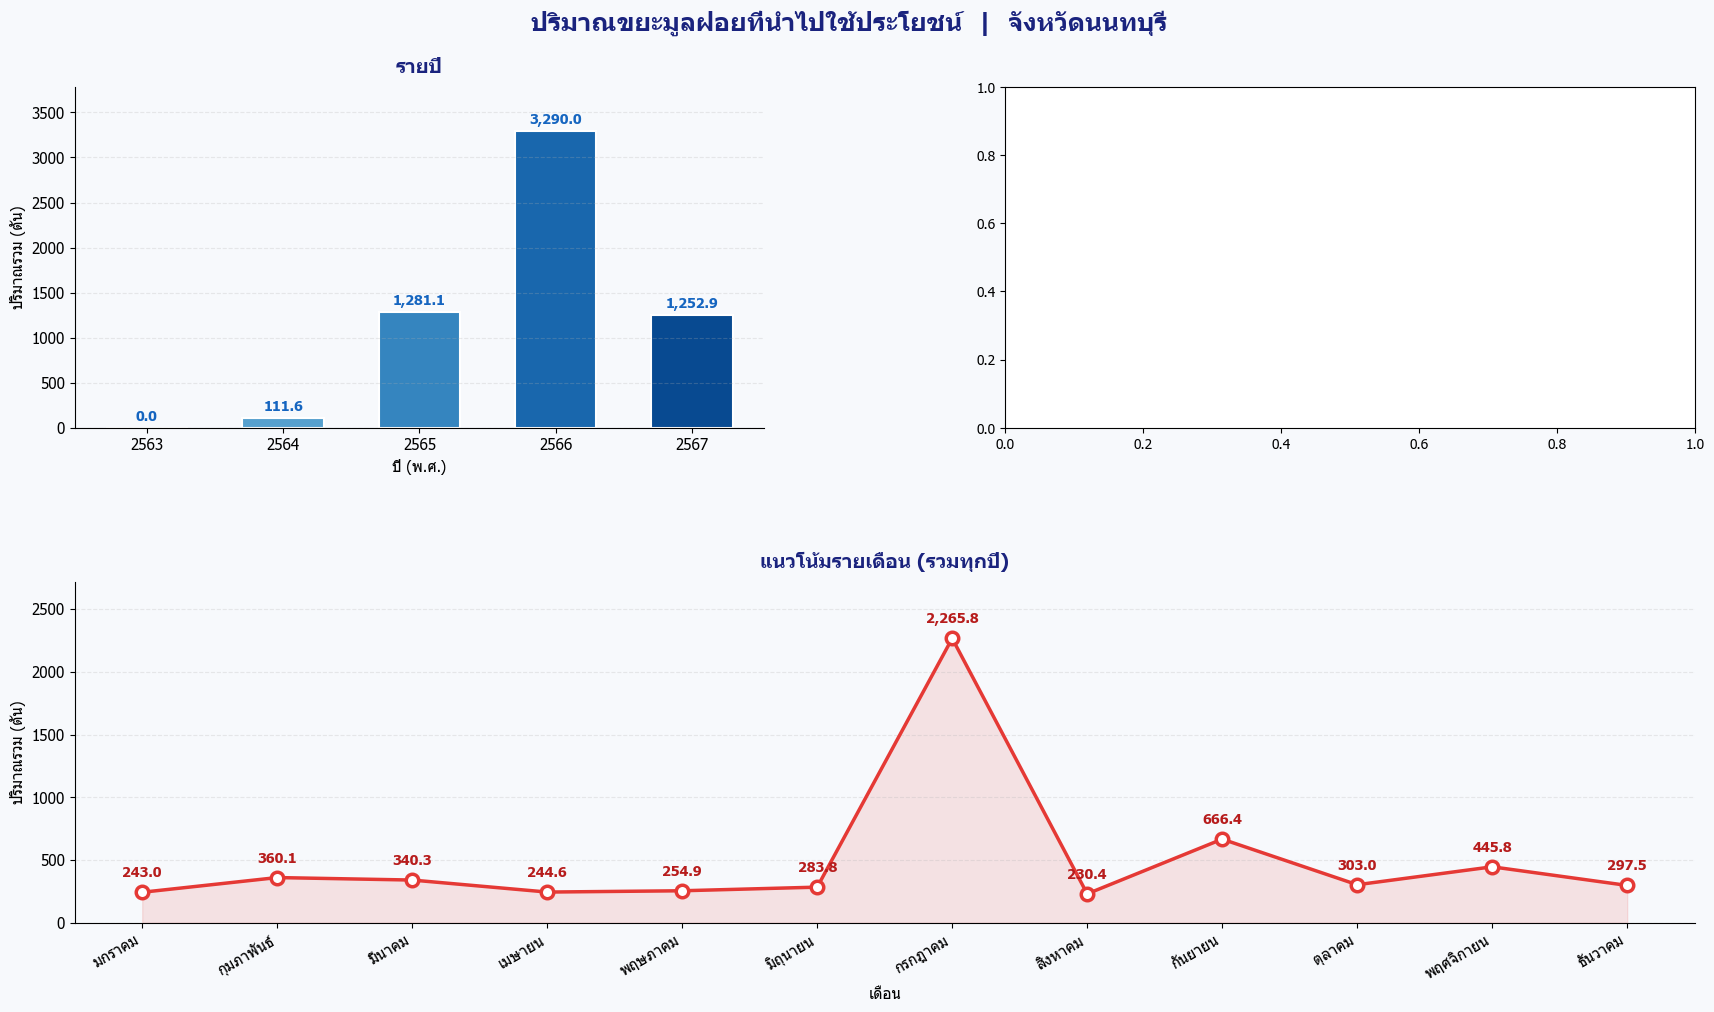

บันทึกภาพสำเร็จ: benefit_visualization.png


In [7]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ---- Thai Font Setup ----
# try Thai fonts in order
# ลองใช้ฟอนต์ภาษาไทยตามลำดับ
thai_font_candidates = ['TH Sarabun New', 'Tahoma', 'Leelawadee UI', 'Arial Unicode MS', 'DejaVu Sans']
available_fonts = {f.name for f in fm.fontManager.ttflist}
chosen_font = next((f for f in thai_font_candidates if f in available_fonts), 'DejaVu Sans')
plt.rcParams['font.family'] = chosen_font
plt.rcParams['axes.unicode_minus'] = False
print(f"ใช้ฟอนต์: {chosen_font}")

# ---- Load & Prepare Data ----
df_viz = pd.read_csv('../data/clean/clean_benefit.csv')

yearly   = df_viz.groupby('ปี')['ขยะนำไปใช้ประโยชน์'].sum().reset_index()
district = (df_viz.groupby('อำเภอ')['ขยะนำไปใช้ประโยชน์']
            .sum().reset_index()
            .sort_values('ขยะนำไปใช้ประโยชน์', ascending=True))

month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
monthly = (df_viz.groupby('เดือน')['ขยะนำไปใช้ประโยชน์']
           .sum().reindex(month_order).fillna(0))

# ---- Figure Layout ----
fig = plt.figure(figsize=(18, 11))
fig.patch.set_facecolor('#F7F9FC')
gs = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.35,
                      left=0.07, right=0.97, top=0.88, bottom=0.12)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

fig.suptitle('ปริมาณขยะมูลฝอยที่นำไปใช้ประโยชน์  |  จังหวัดนนทบุรี',
             fontsize=18, fontweight='bold', color='#1A237E', y=0.95)

def style_ax(ax):
    ax.set_facecolor('#F7F9FC')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    ax.tick_params(labelsize=11)

# ──────────────────────────────────────────────
# Plot 1 : yearly (Bar chart)
# Plot 1 : รายปี (Bar chart)
# ──────────────────────────────────────────────
style_ax(ax1)
ax1.grid(axis='x', alpha=0)  # turn off the horizontal grid — ปิด grid แนวนอน
colors_yr = plt.cm.Blues(np.linspace(0.45, 0.90, len(yearly)))
bars1 = ax1.bar(yearly['ปี'].astype(str), yearly['ขยะนำไปใช้ประโยชน์'],
                color=colors_yr, edgecolor='white', linewidth=1.5, width=0.6)
ax1.set_title('รายปี', fontsize=14, fontweight='bold', pad=10, color='#1A237E')
ax1.set_xlabel('ปี (พ.ศ.)', fontsize=11)
ax1.set_ylabel('ปริมาณรวม (ตัน)', fontsize=11)
y_max = yearly['ขยะนำไปใช้ประโยชน์'].max()
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., h + y_max*0.015,
             f'{h:,.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1565C0')
ax1.set_ylim(0, y_max * 1.15)


# ──────────────────────────────────────────────
# Plot 3 : monthly (Line + fill)
# Plot 3 : รายเดือน (Line + fill)
# ──────────────────────────────────────────────
style_ax(ax3)
ax3.grid(axis='x', alpha=0)
x = np.arange(len(month_order))
ax3.fill_between(x, monthly.values, alpha=0.12, color='#E53935')
ax3.plot(x, monthly.values, 'o-', color='#E53935',
         linewidth=2.5, markersize=9, zorder=3, markerfacecolor='white',
         markeredgewidth=2.5)
# Label each point
for xi, yi in zip(x, monthly.values):
    ax3.annotate(f'{yi:,.1f}', (xi, yi),
                 textcoords='offset points', xytext=(0, 11),
                 ha='center', fontsize=10, fontweight='bold', color='#B71C1C')
ax3.set_title('แนวโน้มรายเดือน (รวมทุกปี)', fontsize=14, fontweight='bold', pad=10, color='#1A237E')
ax3.set_xlabel('เดือน', fontsize=11)
ax3.set_ylabel('ปริมาณรวม (ตัน)', fontsize=11)
ax3.set_xticks(x)
ax3.set_xticklabels(month_order, rotation=30, ha='right', fontsize=11)
ax3.set_xlim(-0.5, len(month_order) - 0.5)
ax3.set_ylim(0, monthly.values.max() * 1.20)

plt.savefig('../figures/benefit_visualization.png', dpi=150, bbox_inches='tight', facecolor='#F7F9FC')
plt.show()
print("บันทึกภาพสำเร็จ: benefit_visualization.png")

---
# Part 3: Additional Charts

The charts above give the overview; this part digs deeper — the next cell sets up the shared chart settings (Thai font, color palette, district colors, helper functions) used in the other notebooks

# ส่วนที่ 3: กราฟเพิ่มเติม

กราฟด้านบนให้ภาพรวม ส่วนนี้เจาะลึกเพิ่มเติม — เซลล์ถัดไปตั้งค่ากราฟร่วม (ฟอนต์ไทย, ชุดสี, สีประจำอำเภอ, ฟังก์ชันช่วย) แบบเดียวกับ notebook อื่น

In [8]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [9]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(2655, 6)


,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะนำไปใช้ประโยชน์
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,0.0
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,0.0
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,0.0
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,0.0
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,0.0


### 3.0 Before starting: most of the data is 0
**What it does:** counts the share of rows with a value of 0 — the statistics show this column's median is 0, meaning most local governments **have/report no** beneficial use of waste in most months, so the totals come from just a few local governments

### 3.0 ข้อสังเกตก่อนเริ่ม: ข้อมูลส่วนใหญ่เป็น 0
**ทำอะไร:** นับสัดส่วนแถวที่มีค่าเป็น 0 — จากสถิติ ค่ามัธยฐานของคอลัมน์นี้คือ 0 หมายความว่า อปท. ส่วนใหญ่ **ไม่มี/ไม่ได้รายงาน** การนำขยะไปใช้ประโยชน์ในเดือนส่วนใหญ่ ผลรวมจึงมาจาก อปท. ไม่กี่แห่ง

In [10]:
col = 'ขยะนำไปใช้ประโยชน์'
zero_share = (viz[col] == 0).mean() * 100
print(f'แถวที่มีค่าเป็น 0: {zero_share:.1f}% ของ {len(viz):,} แถว')
print(f"อปท. ที่เคยมีค่า > 0 อย่างน้อย 1 เดือน: {viz.loc[viz[col] > 0, 'อปท'].nunique()} จาก {viz['อปท'].nunique()} แห่ง")

แถวที่มีค่าเป็น 0: 91.4% ของ 2,655 แถว
อปท. ที่เคยมีค่า > 0 อย่างน้อย 1 เดือน: 16 จาก 47 แห่ง


### 3.2 Stacked bar chart: yearly totals by district
**What it does:** builds a pivot table (rows = year, columns = district) and draws the bars stacked on top of each other

**How to read it:** the full bar height = that year's total, and each color is one district's share — it shows "which district the rise/fall in the total comes from"

### 3.2 กราฟแท่งซ้อน (Stacked Bar): ยอดรายปีแยกตามอำเภอ
**ทำอะไร:** สร้างตาราง pivot (แถว = ปี, คอลัมน์ = อำเภอ) แล้ววาดแท่งซ้อนกัน

**วิธีอ่าน:** ความสูงทั้งแท่ง = ยอดรวมของปีนั้น, แต่ละสีคือส่วนของแต่ละอำเภอ ช่วยให้เห็นว่า "การเพิ่ม/ลดของยอดรวม มาจากอำเภอไหน"

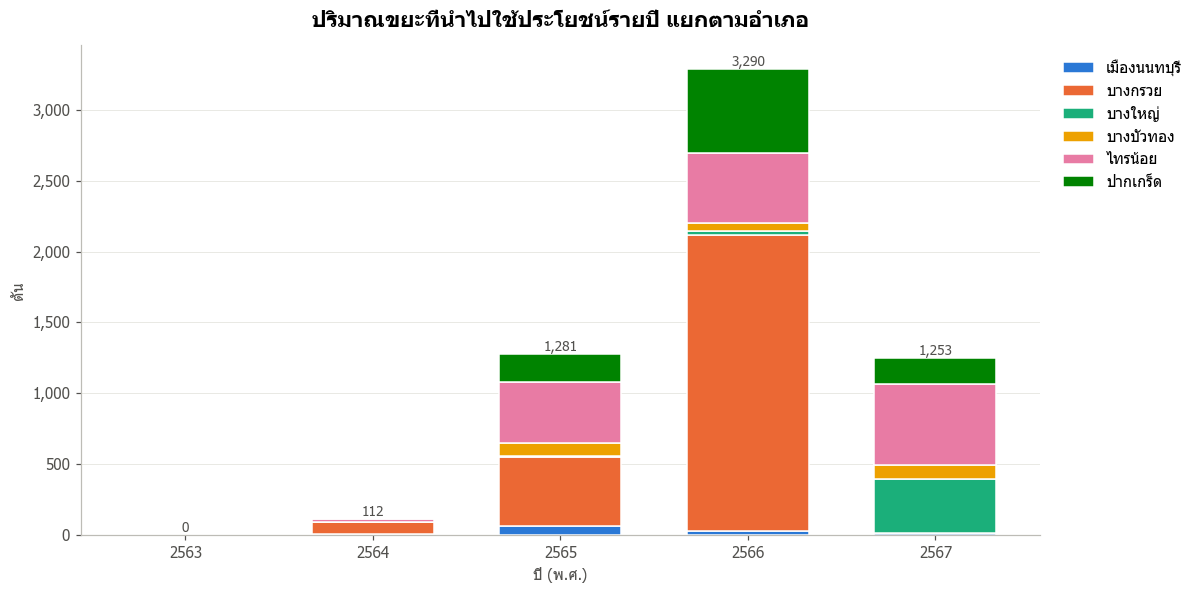

อำเภอ,เมืองนนทบุรี,บางกรวย,บางใหญ่,บางบัวทอง,ไทรน้อย,ปากเกร็ด
ปี,,,,,,
2563,0.0,0.0,0.0,0.0,0.0,0.0
2564,8.5,86.8,0.0,0.0,16.2,0.0
2565,62.0,488.5,4.6,97.4,426.2,202.4
2566,32.2,2082.4,31.0,58.8,490.5,595.2
2567,14.6,0.0,382.1,97.1,570.0,189.0


In [11]:
col = 'ขยะนำไปใช้ประโยชน์'
pivot = (viz.pivot_table(index='ปี', columns='อำเภอ', values=col, aggfunc='sum')
            .reindex(columns=[d for d in DIST_ORDER if d in set(viz['อำเภอ'])]))

fig, ax = plt.subplots(figsize=(11, 5.5))
totals = stacked_bar(ax, pivot)
for i, t in enumerate(totals):
    ax.text(i, t, f'{t:,.0f}', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.yaxis.set_major_formatter(fmt_k)
ax.set_title('ปริมาณขยะที่นำไปใช้ประโยชน์รายปี แยกตามอำเภอ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()
pivot.round(1)

### 3.3 Horizontal bar + pie chart: comparison by district (all years combined)
**What it does:** sums waste put to beneficial use for each district over all years
- **Horizontal bar chart**, sorted from smallest to largest → compares "size" precisely
- **Pie chart** → shows the "share": what % of the province each district accounts for (each district keeps the same color as in the other charts)

### 3.3 กราฟแท่งแนวนอน + แผนภูมิวงกลม: เปรียบเทียบรายอำเภอ (รวมทุกปี)
**ทำอะไร:** รวมปริมาณขยะที่นำไปใช้ประโยชน์ของแต่ละอำเภอตลอดทุกปี
- **กราฟแท่งแนวนอน** เรียงจากน้อยไปมาก → เทียบ "ขนาด" ได้แม่นยำ
- **แผนภูมิวงกลม (Pie chart)** → ดู "สัดส่วน" ว่าแต่ละอำเภอคิดเป็นกี่ % ของทั้งจังหวัด (สีของแต่ละอำเภอเหมือนกับกราฟอื่น)

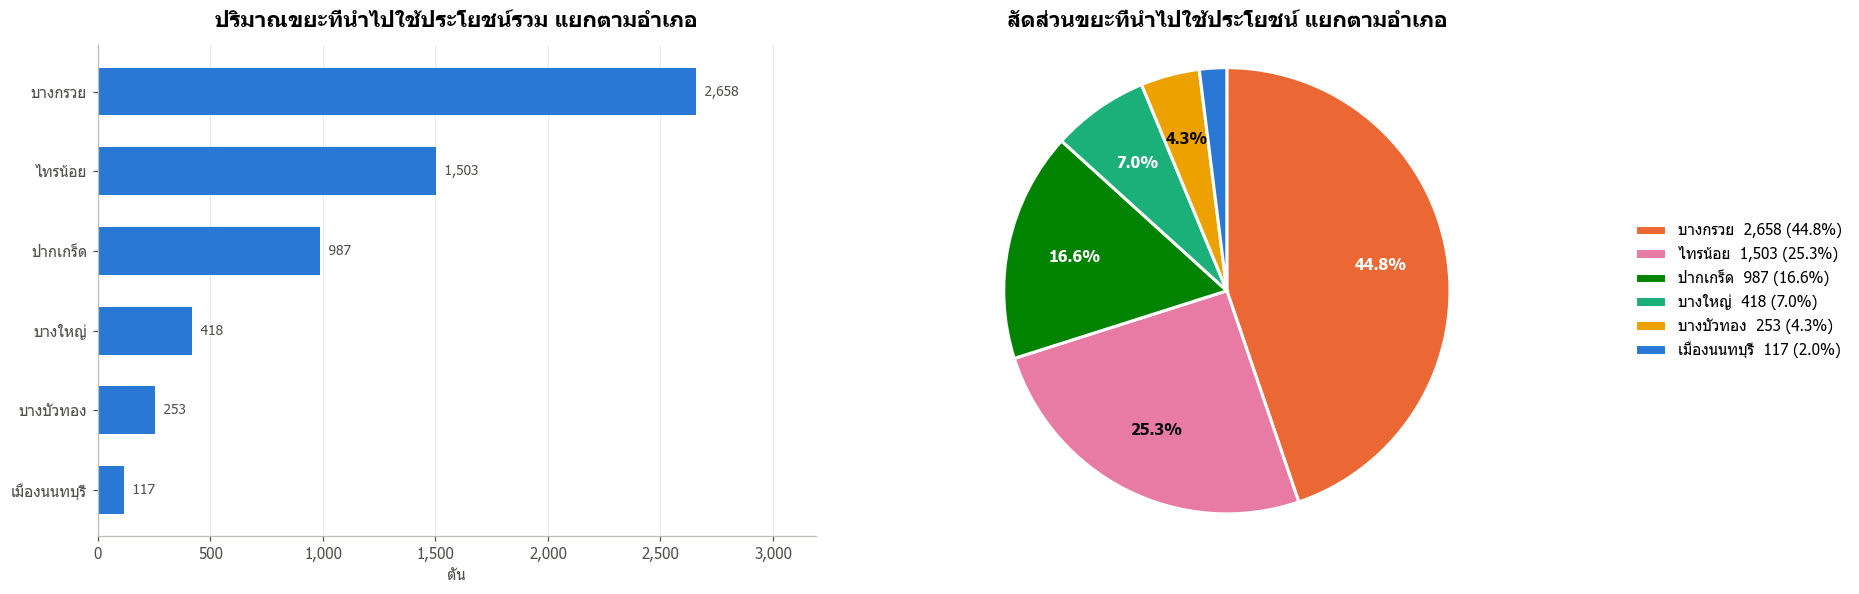

In [12]:
col = 'ขยะนำไปใช้ประโยชน์'
by_dist = viz.groupby('อำเภอ')[col].sum().sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1, 1.1]})
bars = ax1.barh(by_dist.index, by_dist.values, color=PALETTE[0], height=0.6)
bar_labels(ax1, bars, horizontal=True)
ax1.set_xlim(0, by_dist.max() * 1.2)
ax1.xaxis.set_major_formatter(fmt_k); ax1.grid(axis='y', visible=False)
ax1.set_title('ปริมาณขยะที่นำไปใช้ประโยชน์รวม แยกตามอำเภอ'); ax1.set_xlabel('ตัน')

share = by_dist[by_dist > 0].sort_values(ascending=False)
pie_chart(ax2, share.values, share.index, colors=[DIST_COLOR.get(d, GRAY) for d in share.index],
          title='สัดส่วนขยะที่นำไปใช้ประโยชน์ แยกตามอำเภอ')
plt.tight_layout(); plt.show()

### 3.4 Bar chart: seasonal pattern (average by month)
**What it does:** first totals each "year-month", then averages the same month across years (e.g. every January averaged together)

**How to read it:** bars above the dashed line (the average of all months) = months with more than usual — useful for planning staff/collection trucks by season

### 3.4 กราฟแท่ง: รูปแบบตามฤดูกาล (ค่าเฉลี่ยรายเดือน)
**ทำอะไร:** หายอดรวมของแต่ละ "ปี-เดือน" ก่อน แล้วเฉลี่ยข้ามปีของเดือนเดียวกัน (เช่น ม.ค. ทุกปีมาเฉลี่ยกัน)

**วิธีอ่าน:** แท่งที่สูงกว่าเส้นประ (ค่าเฉลี่ยทุกเดือน) = เดือนที่มีปริมาณมากกว่าปกติ ช่วยวางแผนกำลังคน/รถเก็บขนตามฤดูกาล

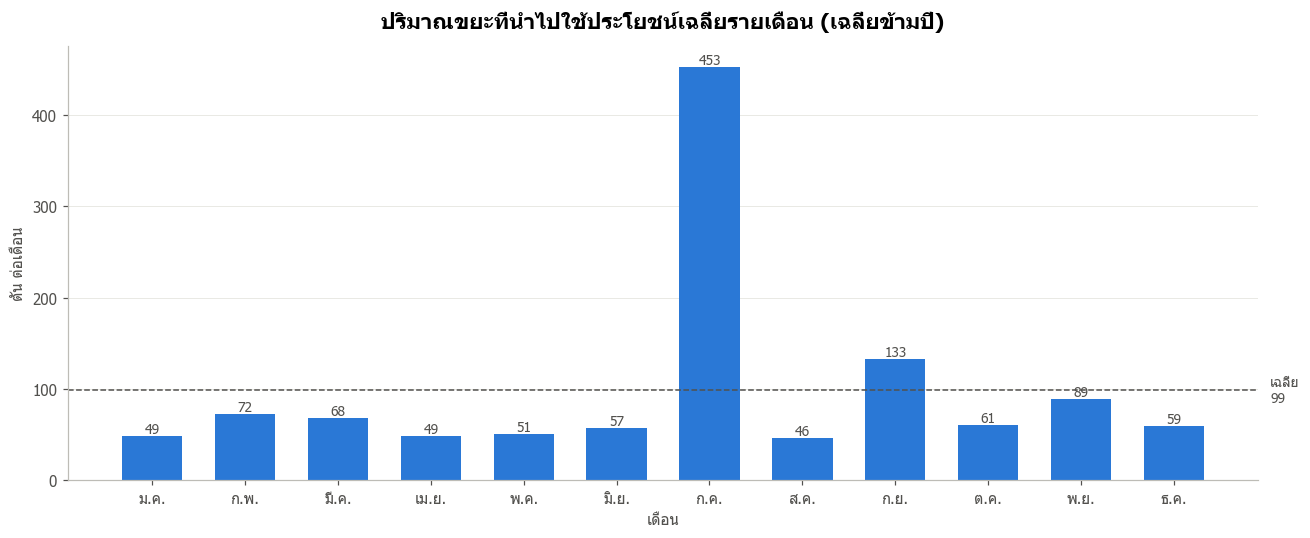

In [13]:
col = 'ขยะนำไปใช้ประโยชน์'
ym = viz.groupby(['ปี', 'เดือน'])[col].sum().unstack('เดือน').reindex(columns=MONTHS)
avg = ym.mean()

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(MONTHS_SHORT, avg.values, color=PALETTE[0], width=0.65)
bar_labels(ax, bars)
ref_line(ax, avg.mean(), f'เฉลี่ย\n{avg.mean():,.0f}')
ax.yaxis.set_major_formatter(fmt_k); ax.grid(axis='x', visible=False)
ax.set_title('ปริมาณขยะที่นำไปใช้ประโยชน์เฉลี่ยรายเดือน (เฉลี่ยข้ามปี)')
ax.set_xlabel('เดือน'); ax.set_ylabel('ตัน ต่อเดือน')
plt.tight_layout(); plt.show()

### 3.5 Heatmap: year × month
**What it does:** shows the total for every month of every year as a colored table (darker = more)

**How to read it:** read across a row to see the seasonality within a year, read down a column to compare the same month across years. Cells that are unusually light/dark may be months with missing data or special events

### 3.5 Heatmap: ปี × เดือน
**ทำอะไร:** แสดงยอดรวมของทุกเดือนในทุกปีเป็นตารางสี (สีเข้ม = ปริมาณมาก)

**วิธีอ่าน:** อ่านตามแถวเพื่อดูฤดูกาลภายในปี อ่านตามคอลัมน์เพื่อเทียบเดือนเดียวกันข้ามปี ช่องที่สีอ่อน/เข้มผิดปกติอาจเป็นเดือนที่ข้อมูลขาดหรือมีเหตุการณ์พิเศษ

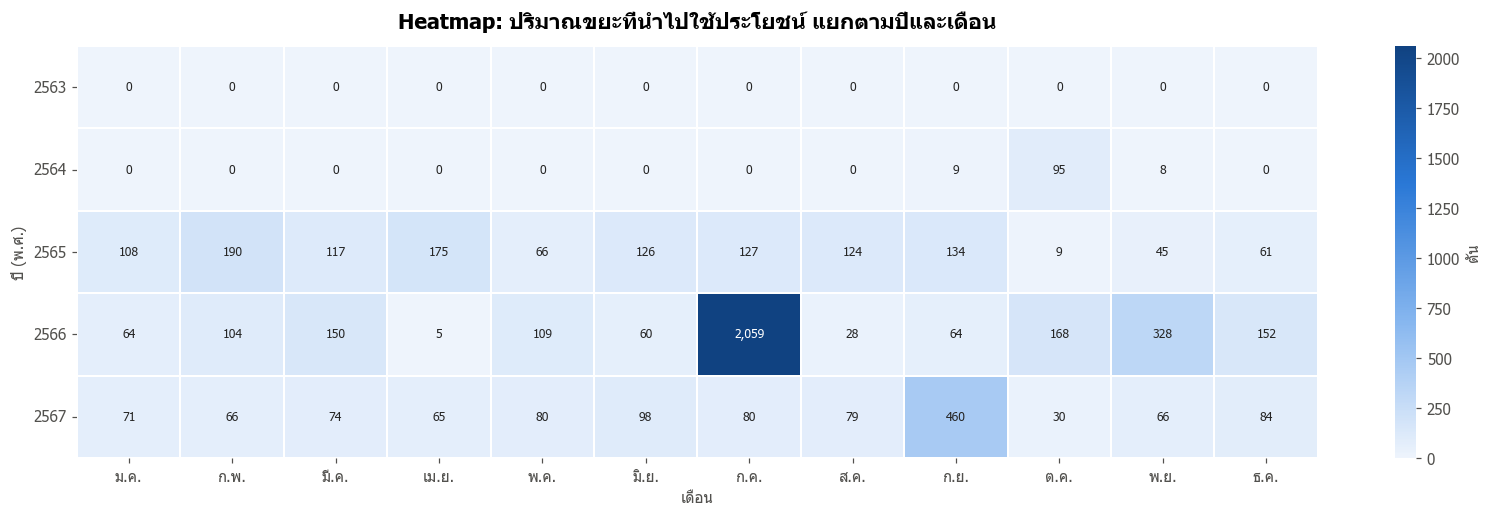

In [14]:
col = 'ขยะนำไปใช้ประโยชน์'
ym = viz.groupby(['ปี', 'เดือน'])[col].sum().unstack('เดือน').reindex(columns=MONTHS)

fig, ax = plt.subplots(figsize=(15, 4.8))
sns.heatmap(ym.set_axis(MONTHS_SHORT, axis=1), annot=True, fmt=',.0f', cmap=SEQ_CMAP,
            linewidths=1, linecolor='white', annot_kws={'fontsize': 8},
            cbar_kws={'label': 'ตัน'}, ax=ax)
ax.set_title('Heatmap: ปริมาณขยะที่นำไปใช้ประโยชน์ แยกตามปีและเดือน')
ax.set_xlabel('เดือน'); ax.set_ylabel('ปี (พ.ศ.)')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()

### 3.6 Horizontal bar chart: top 10 local governments by waste put to beneficial use (all years combined)
**What it does:** sums the values per local government and picks the top 10 (`nlargest(10)`)

**How to read it:** shows which local governments most of the amount is concentrated in — useful for prioritizing areas (the number in brackets is the % of the province total)

### 3.6 กราฟแท่งแนวนอน: 10 อปท. ที่มีปริมาณขยะที่นำไปใช้ประโยชน์สูงสุด (รวมทุกปี)
**ทำอะไร:** รวมค่าราย อปท. แล้วเลือก 10 อันดับแรก (`nlargest(10)`)

**วิธีอ่าน:** บอกว่าปริมาณส่วนใหญ่กระจุกตัวอยู่ที่ อปท. ใด — ใช้จัดลำดับความสำคัญของพื้นที่ (ตัวเลขในวงเล็บคือ % ของยอดรวมทั้งจังหวัด)

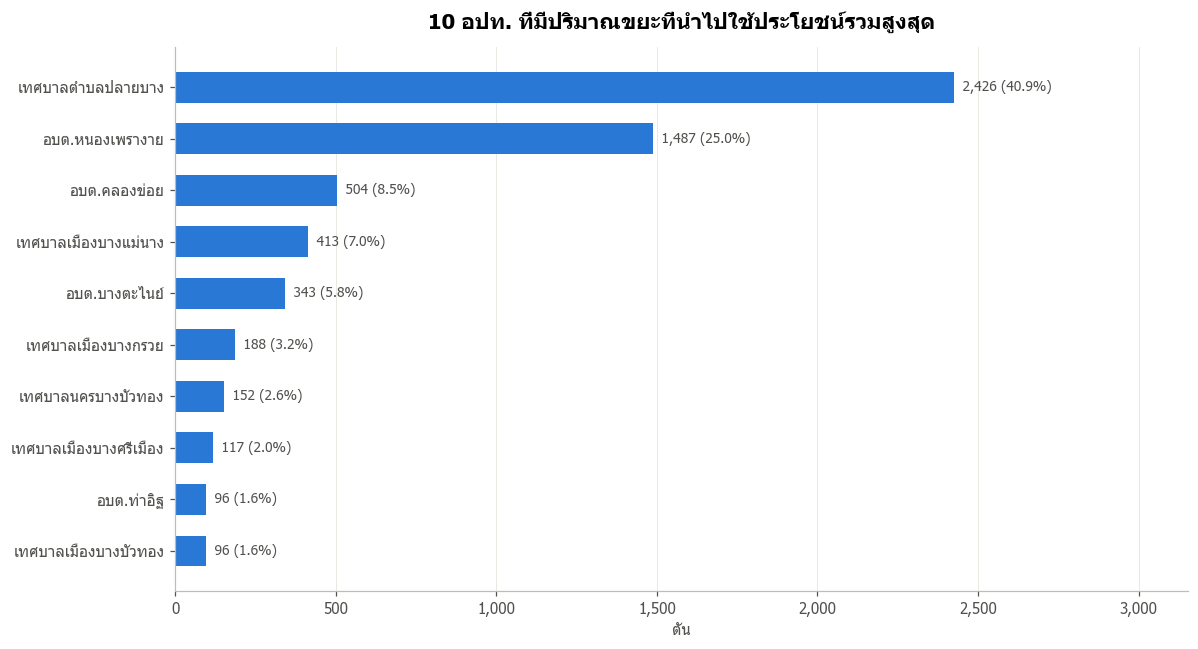

10 อันดับแรกคิดเป็น 98.1% ของยอดรวมทั้งจังหวัด (จาก 47 อปท.)


In [15]:
col = 'ขยะนำไปใช้ประโยชน์'
by_apt = viz.groupby('อปท')[col].sum()
top = by_apt.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top.index, top.values, color=PALETTE[0], height=0.6)
for b, v in zip(bars, top.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f'  {v:,.0f} ({v / by_apt.sum() * 100:.1f}%)',
            va='center', fontsize=9, color=TEXT)
ax.set_xlim(0, top.max() * 1.3)
ax.xaxis.set_major_formatter(fmt_k); ax.grid(axis='y', visible=False)
ax.set_title('10 อปท. ที่มีปริมาณขยะที่นำไปใช้ประโยชน์รวมสูงสุด'); ax.set_xlabel('ตัน')
plt.tight_layout(); plt.show()
print(f'10 อันดับแรกคิดเป็น {top.sum() / by_apt.sum() * 100:.1f}% ของยอดรวมทั้งจังหวัด (จาก {by_apt.size} อปท.)')

### Number of local governments with beneficial use of waste (> 0) each year
**How to read it:** shows local-government "participation" — if the number grows, sorting/waste-bank programs are expanding even if the totals are still low

### จำนวน อปท. ที่มีการนำขยะไปใช้ประโยชน์ (> 0) ในแต่ละปี
**วิธีอ่าน:** แสดง "การมีส่วนร่วม" ของ อปท. — ถ้าจำนวนเพิ่มขึ้น แปลว่าโครงการคัดแยก/ธนาคารขยะขยายตัว แม้ยอดรวมจะยังไม่สูง

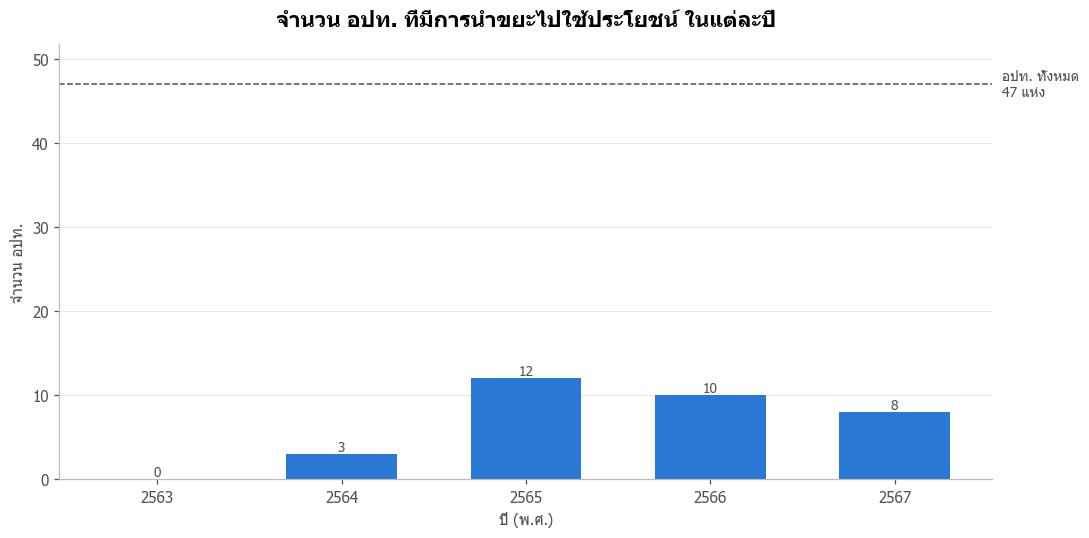

In [16]:
col = 'ขยะนำไปใช้ประโยชน์'
active = viz[viz[col] > 0].groupby('ปี')['อปท'].nunique().reindex(sorted(viz['ปี'].unique()), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(active.index.astype(str), active.values, color=PALETTE[0], width=0.6)
bar_labels(ax, bars)
ax.set_ylim(0, viz['อปท'].nunique() * 1.1)
ref_line(ax, viz['อปท'].nunique(), f"อปท. ทั้งหมด\n{viz['อปท'].nunique()} แห่ง")
ax.grid(axis='x', visible=False)
ax.set_title('จำนวน อปท. ที่มีการนำขยะไปใช้ประโยชน์ ในแต่ละปี')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('จำนวน อปท.')
plt.tight_layout(); plt.show()

### beneficial use of waste rate relative to all municipal solid waste (% by district × year)
**What it does:** uses the municipal solid waste data (`clean_community.csv`) as the denominator and calculates

`rate (%) = amount of beneficial use of waste ÷ total municipal solid waste × 100`

split by district and year, shown as a heatmap (darker = higher share)

**How to read it:** this number answers "what % of all the waste generated was separated/handled as beneficial use of waste" — a fairer measure of sorting performance than raw amounts, because large districts naturally produce more waste

### อัตราการนำขยะไปใช้ประโยชน์ต่อขยะมูลฝอยชุมชนทั้งหมด (% รายอำเภอ × ปี)
**ทำอะไร:** นำข้อมูลขยะมูลฝอยชุมชน (`clean_community.csv`) มาเป็นตัวหาร แล้วคำนวณ

`อัตรา (%) = ปริมาณการนำขยะไปใช้ประโยชน์ ÷ ขยะมูลฝอยชุมชนทั้งหมด × 100`

แยกตามอำเภอและปี แสดงเป็น heatmap (สีเข้ม = สัดส่วนสูง)

**วิธีอ่าน:** ตัวเลขนี้ตอบคำถามว่า "ขยะที่เกิดขึ้นทั้งหมด ถูกแยก/จัดการเป็นการนำขยะไปใช้ประโยชน์ได้กี่ %" — เป็นตัวชี้วัดประสิทธิภาพการคัดแยกที่ยุติธรรมกว่าการดูปริมาณตรง ๆ เพราะอำเภอใหญ่ย่อมมีขยะมากอยู่แล้ว

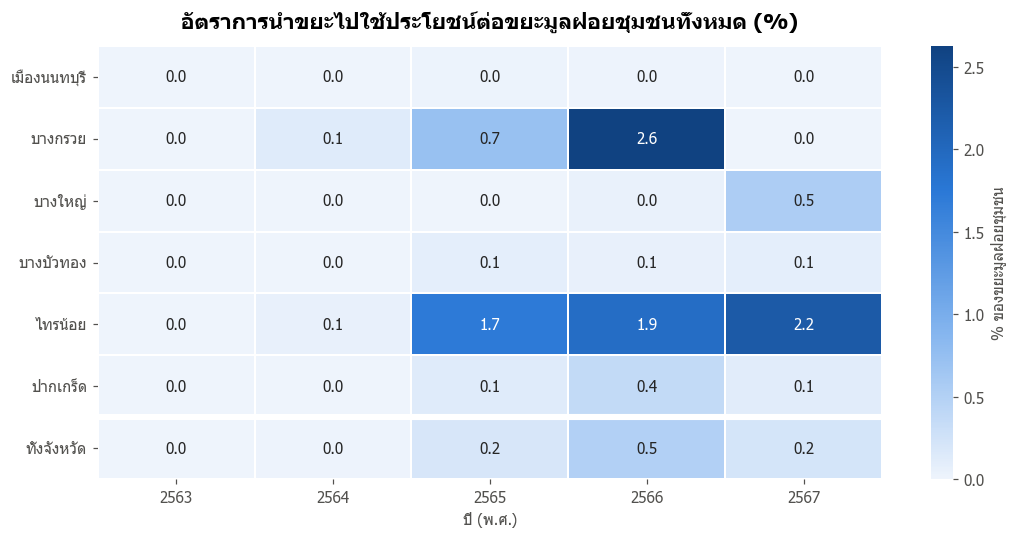

ปี,2563,2564,2565,2566,2567
อำเภอ,,,,,
เมืองนนทบุรี,0.0,0.00,0.03,0.02,0.01
บางกรวย,0.0,0.13,0.72,2.63,0.00
บางใหญ่,0.0,0.00,0.01,0.05,0.54
บางบัวทอง,0.0,0.00,0.08,0.05,0.09
ไทรน้อย,0.0,0.06,1.72,1.92,2.23
ปากเกร็ด,0.0,0.00,0.13,0.37,0.12
ทั้งจังหวัด,0.0,0.02,0.20,0.51,0.22


In [17]:
col = 'ขยะนำไปใช้ประโยชน์'
comm = pd.read_csv('../data/clean/clean_community.csv')
comm_dy = comm.groupby(['อำเภอ', 'ปี'])['ขยะมูลฝอยชุมชน(ตัน)'].sum()
part_dy = viz.groupby(['อำเภอ', 'ปี'])[col].sum()
rate = (part_dy / comm_dy * 100).unstack('ปี').reindex([d for d in DIST_ORDER if d in set(viz['อำเภอ'])])

overall = viz.groupby('ปี')[col].sum() / comm.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum() * 100
rate.loc['ทั้งจังหวัด'] = overall

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(rate, annot=True, fmt='.1f', cmap=SEQ_CMAP, linewidths=1, linecolor='white',
            cbar_kws={'label': '% ของขยะมูลฝอยชุมชน'}, ax=ax)
ax.axhline(len(rate) - 1, color='white', linewidth=4)
ax.set_title('อัตราการนำขยะไปใช้ประโยชน์ต่อขยะมูลฝอยชุมชนทั้งหมด (%)')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()
rate.round(2)

---
## Key Findings

1. **The amounts are still very small** — the peak in 2566 (2023) is ~3,290 tonnes, only **~0.5% of all municipal solid waste** (0 in 2563)
2. **Highly concentrated** — Plai Bang Subdistrict Municipality (~41%) and Nong Phrao Ngai SAO (~25%) together account for more than two thirds of the province
3. **Few local governments take part** — at most 12 of 47 (2565), dropping to 8 in 2567
4. **Opportunity:** Mueang Nonthaburi, which has the most waste, has almost no beneficial use (~0%) — the first area where waste-bank/composting programs should be promoted

## สรุปข้อค้นพบ

1. **ปริมาณยังน้อยมาก** — สูงสุดปี 2566 ~3,290 ตัน คิดเป็นเพียง **~0.5% ของขยะมูลฝอยชุมชนทั้งหมด** (ปี 2563 เป็น 0)
2. **กระจุกตัวสูง** — เทศบาลตำบลปลายบาง (~41%) และ อบต.หนองเพรางาย (~25%) รวมกันเกิน 2 ใน 3 ของทั้งจังหวัด
3. **อปท. ที่มีกิจกรรมนี้ยังน้อย** — สูงสุด 12 แห่งจาก 47 แห่ง (ปี 2565) และลดลงเหลือ 8 แห่งในปี 2567
4. **โอกาสพัฒนา:** อำเภอเมืองนนทบุรีซึ่งมีขยะมากที่สุดแทบไม่มีการนำขยะไปใช้ประโยชน์ (~0%) เป็นพื้นที่ที่ควรส่งเสริมโครงการธนาคารขยะ/ปุ๋ยหมักก่อน